In [107]:
# In dev mode, run this
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [108]:
import numpy as np
import networkx as nx

import matplotlib as mpl
from matplotlib import pyplot as plt

import propnetscore.node_selection as ns
from propnetscore.plotting import plot_task, plot_task_aligned

## NetSciAbstract

In [135]:
G = nx.Graph()
G.add_nodes_from([i for i in range(10)])
G.add_edges_from([(0,1),(0,2),(0,4),(1,4),(2,4),(3,4),(4,5),(5,6),(5,9),(6,7),(6,9),(6,8),(8,9)])
G.remove_node(9)
G.add_edge(7,5)
G.add_node(9)
G.add_edges_from([(1,9),(4,9)])

Laplacian Spectrum:
[0.   0.26 1.   1.15 1.59 3.   3.4  4.1  4.41 7.09]


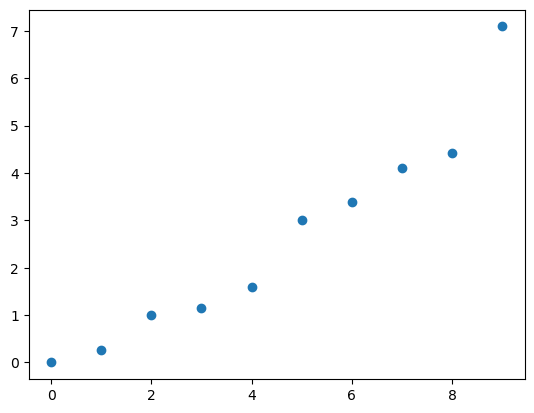

In [136]:
# Spectrum of Karate club network

L = nx.laplacian_matrix(G).toarray()
eigenvalues = np.linalg.eigvalsh(L)  # eigvalsh for symmetric matrices
eigenvalues = np.sort(eigenvalues)

print("Laplacian Spectrum:")
print(np.round(eigenvalues, 2))

plt.scatter(np.arange(len(eigenvalues)), eigenvalues)

In [140]:
mu = eigenvalues[2]

In [112]:
adjacency_matrix = nx.to_numpy_array(G)

In [113]:
# Task a

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.25
prediction[1] = 0.25
prediction[2] = 0.25
prediction[4] = 0.25


assert np.allclose(sum(prediction), 1)

task_a = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [114]:
# Task b

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.25
prediction[2] = 0.25
prediction[4] = 0.25
prediction[3] = 0.25


assert np.allclose(sum(prediction), 1)

task_b = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [115]:
# Task c

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.25
prediction[5] = 0.25
prediction[4] = 0.25
prediction[3] = 0.25

assert np.allclose(sum(prediction), 1)

task_c = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [116]:
# Task d

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[1] = 0.25
prediction[2] = 0.25
prediction[4] = 0.25
prediction[3] = 0.25

assert np.allclose(sum(prediction), 1)

task_d = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [117]:
# Task e

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[1] = 0.25
prediction[2] = 0.25
prediction[4] = 0.25
prediction[5] = 0.25

assert np.allclose(sum(prediction), 1)

task_e = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [118]:
# Task f

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
"""
prediction[7] = 0.25
prediction[6] = 0.25
prediction[9] = 0.25
prediction[5] = 0.25
"""
prediction[9] = 0.25
prediction[2] = 0.25
prediction[4] = 0.25
prediction[5] = 0.25

assert np.allclose(sum(prediction), 1)

task_f = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [119]:
scores = [
            "logarithmic",
            "brier", 
            #{"laplace": {"convention": "positive"}}, 
            "resistance", 
            #{"diffusion": {"tau": 0.01, "convention": "positive", "mu": mu}}, 
            {"diffusion": {"tau": 0.1, "convention": "positive", "mu": mu}}, 
            {"diffusion": {"tau": 1, "convention": "positive", "mu": mu}}, 
            {"diffusion": {"tau": 10, "convention": "positive", "mu": mu}}
        ]

In [120]:
np.shape(task_f.resistance)

()

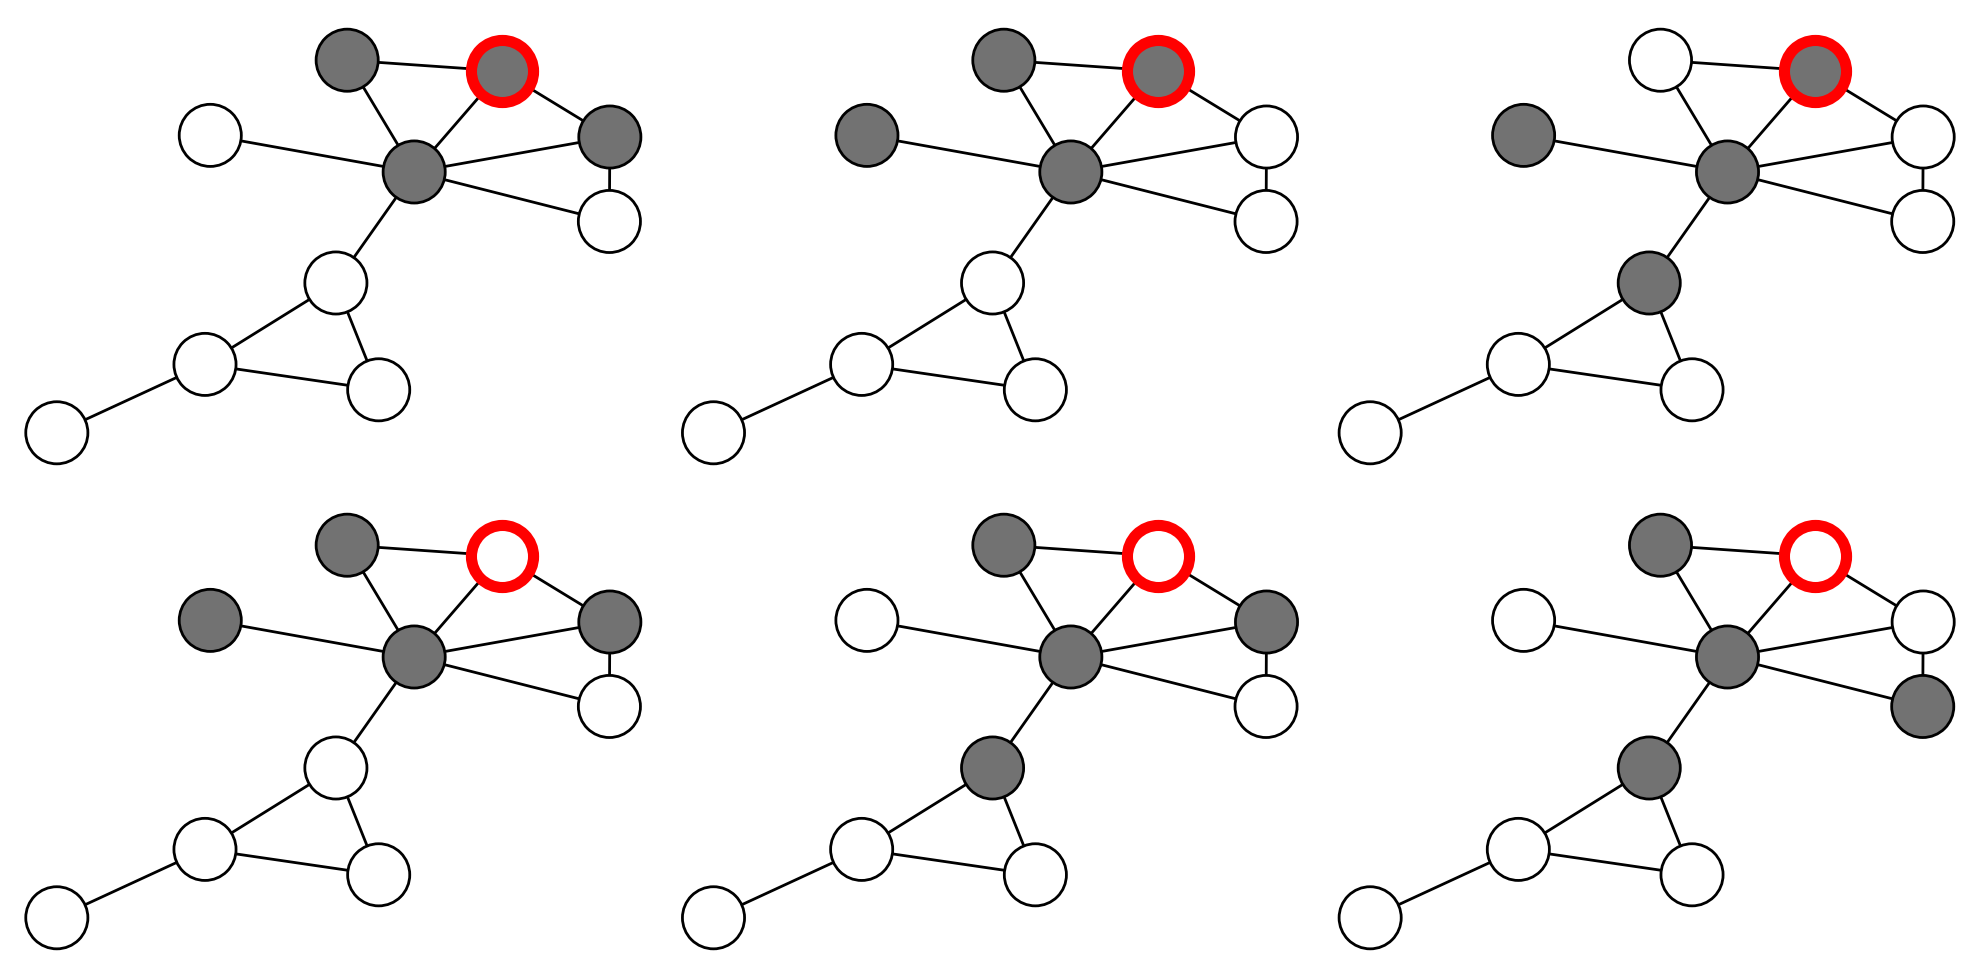

In [121]:
fig, axs = plt.subplots(2, 3, figsize=(10, 5), dpi=200)

for task, ax in zip([task_a, task_b, task_c, task_d, task_e, task_f], axs.flatten()):
    plot_task_aligned(
        ax, G, node_probs=task.node_probs, true_node=task.true_node, 
        labels=None, colorbar=False, contrast=1, max_prob=0.4, prob_color="Grays", true_color="red", 
        scores=[], 
        score_pos="top"
    )
    ax.set_axis_off()  # optional, already done in plot_task

plt.tight_layout()

#plt.savefig("images/toy_graphs.pdf", format="pdf")
plt.show()

In [122]:
scores = [
            #"logarithmic",
            {"top_k_error_rate": {"k": 4}},
            "brier", 
            #{"laplace": {"convention": "positive"}}, 
            "resistance", 
            #{"diffusion": {"tau": 0.01, "convention": "positive", "mu": mu}}, 
            {"diffusion": {"tau": 0.1, "convention": "positive", "mu": mu}}, 
            {"diffusion": {"tau": 1, "convention": "positive", "mu": mu}}, 
            {"diffusion": {"tau": 10, "convention": "positive", "mu": mu}}
        ]

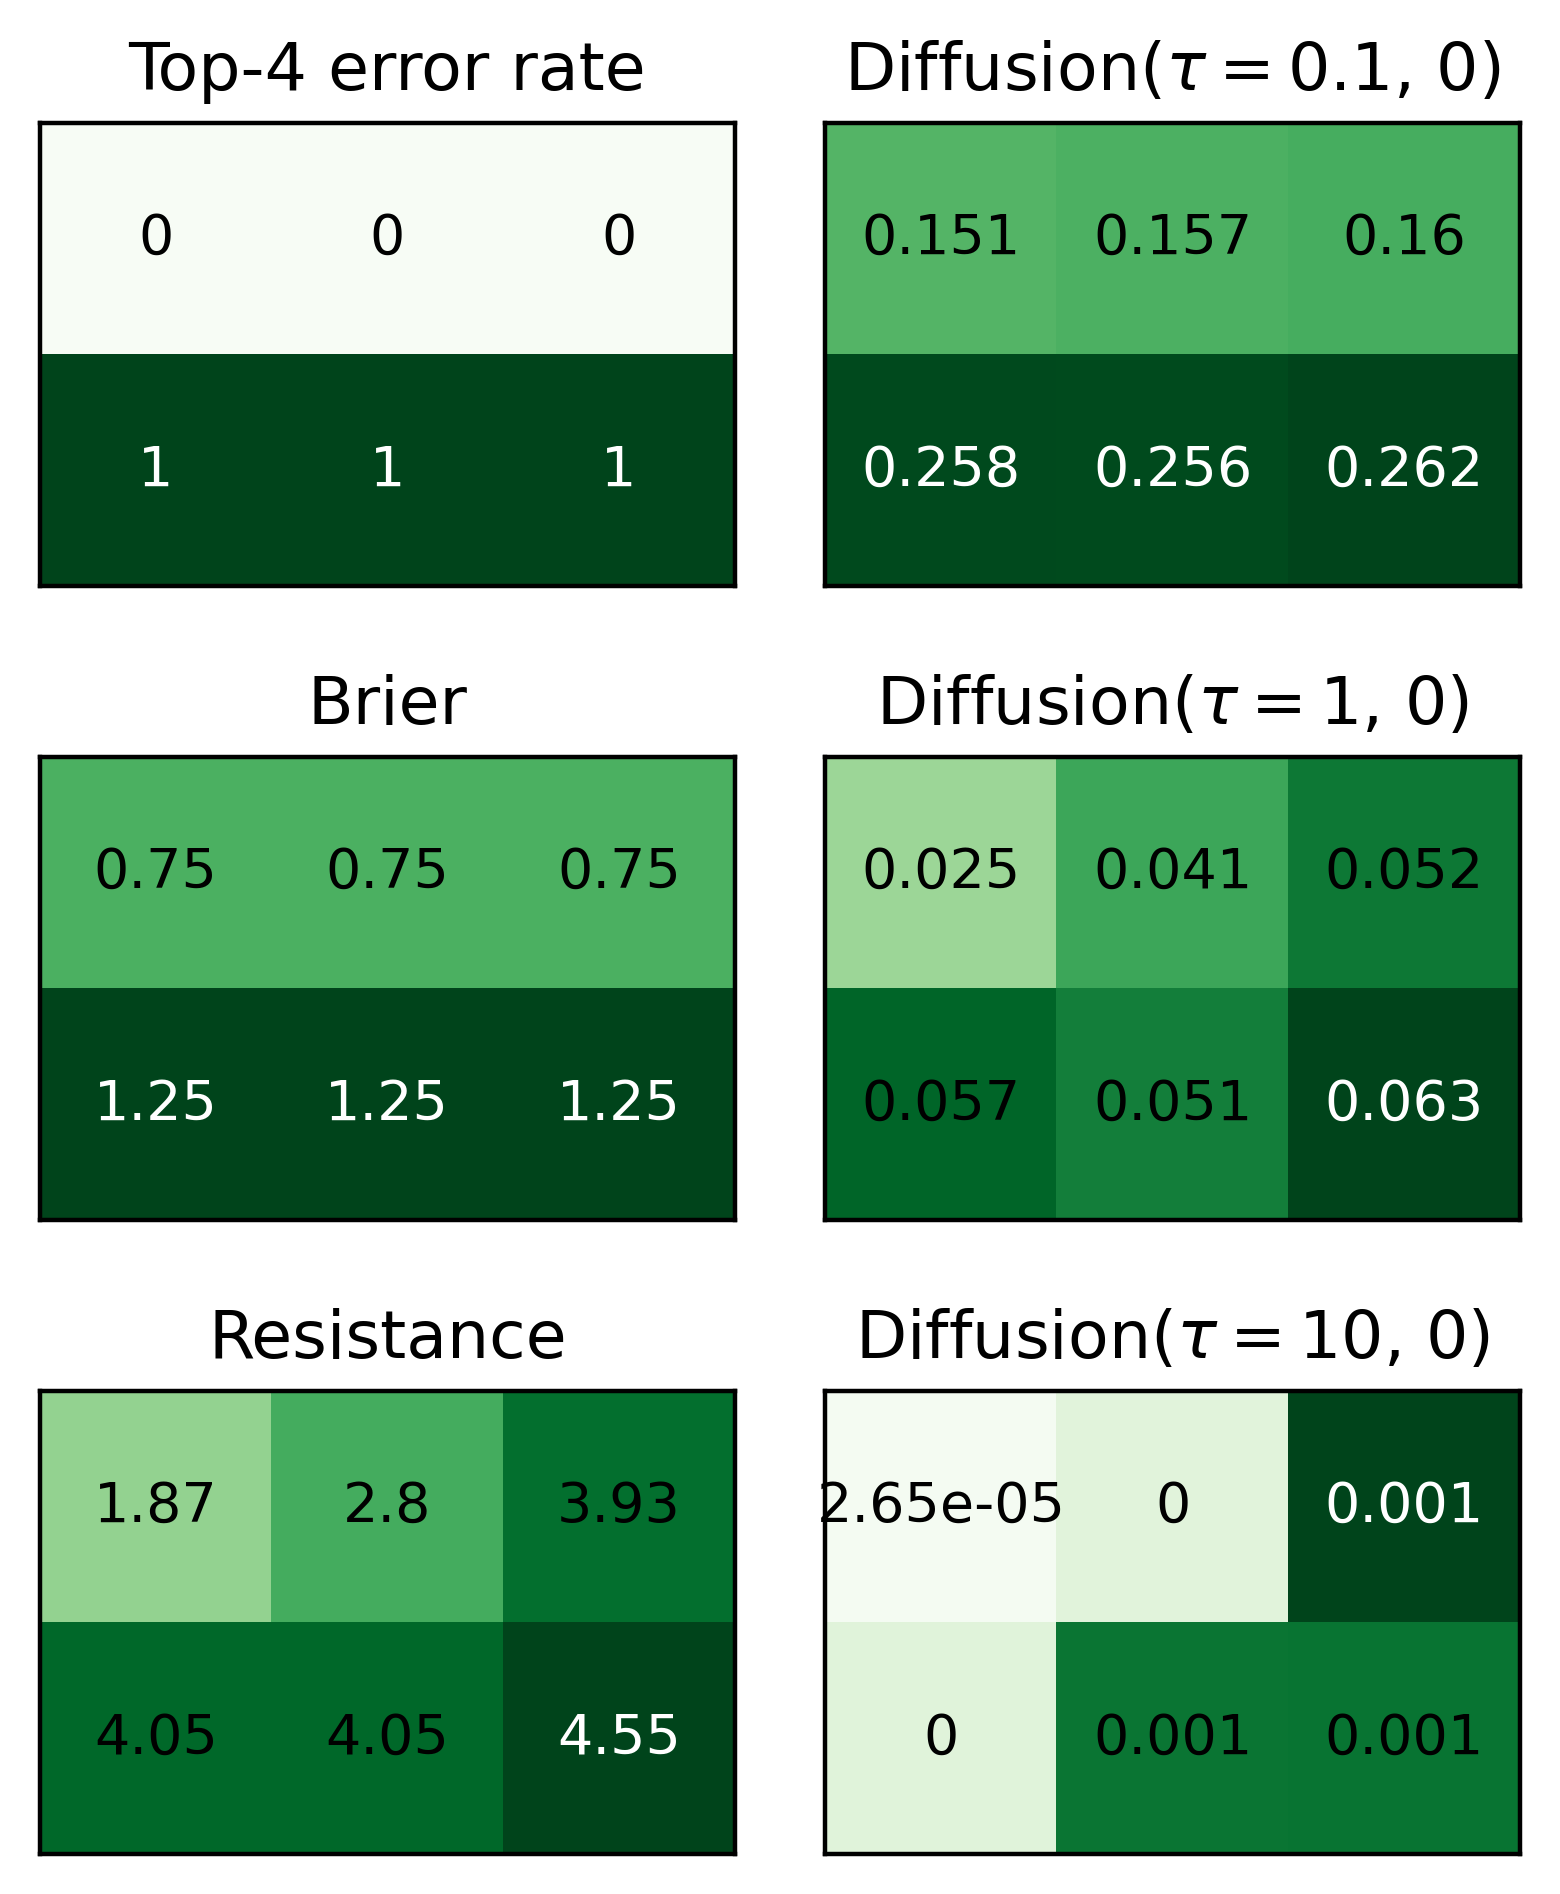

In [123]:
fig, axs = plt.subplots(3, 2, figsize=(4, 5), dpi=400)

score_ix = 0
for col in range(axs.shape[1]):
    for row in range(axs.shape[0]):
        ax = axs[row, col]
        entry = scores[score_ix]
        score_ix += 1
    
        # Handle both "resistance" and {"diffusion": {"alpha": 0.1}}
        if isinstance(entry, str):
            name, kwargs = entry, {}
        elif isinstance(entry, dict):
            if len(entry) != 1:
                raise ValueError(f"Invalid score entry: {entry}")
            name, kwargs = next(iter(entry.items()))
        else:
            raise TypeError(f"Unsupported score format: {entry}")
    
        # Build label with unnamed parameter values
        if kwargs:
            param_str = "(" + ", ".join(str(v) for v in kwargs.values()) + ")"
        else:
            param_str = ""

        if name in ["top_k_error_rate"]:
            method_name = name
            name = f"Top-{kwargs['k']} error rate"
            param_str = ""
        else:
            method_name = f"{name}_score"
        if name in ["diffusion"]:
            number = param_str[1:-1]
            param_str = r'($\tau=$' + number + ')'
        method_specs = str.capitalize(f"{name}{param_str}".replace(", positive", ""))
        
    
        values = []
        for task in [task_a, task_b, task_c, task_d, task_e, task_f]:
            value = getattr(task, method_name)(**kwargs)
            values.append(value)
    
        data = np.array(values).reshape(2, 3)
        data_no_inf = data.copy()
        data_no_inf[data_no_inf == np.inf] = 1e3
        values = []
        
        proportion = 1
        vmax = proportion * data_no_inf.max()
        
        ax.imshow(data_no_inf, vmin=0, vmax=vmax, cmap="Greens")
    
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                val = data[i, j]
                text_color = "white" if val / vmax > 0.9 else "black"
                
                # Format to 3 significant digits, then truncate decimals if needed
                formatted = f"{val:.3g}"
                # Convert scientific notation like 1.23e+04 to 12300
                if 'e' in formatted:
                    # Keep it as is for scientific notation
                    pass
                else:
                    # Round to max 3 decimal places
                    formatted = f"{float(formatted):.3f}".rstrip('0').rstrip('.')
                
                ax.text(j, i, formatted,
                         ha="center", va="center", color=text_color)
                
        ax.set_title(method_specs)
        ax.get_yaxis().set_visible(False)
        ax.get_xaxis().set_visible(False)
    
plt.tight_layout()

#plt.savefig("images/toy_table_vert.pdf", format="pdf")
plt.show()

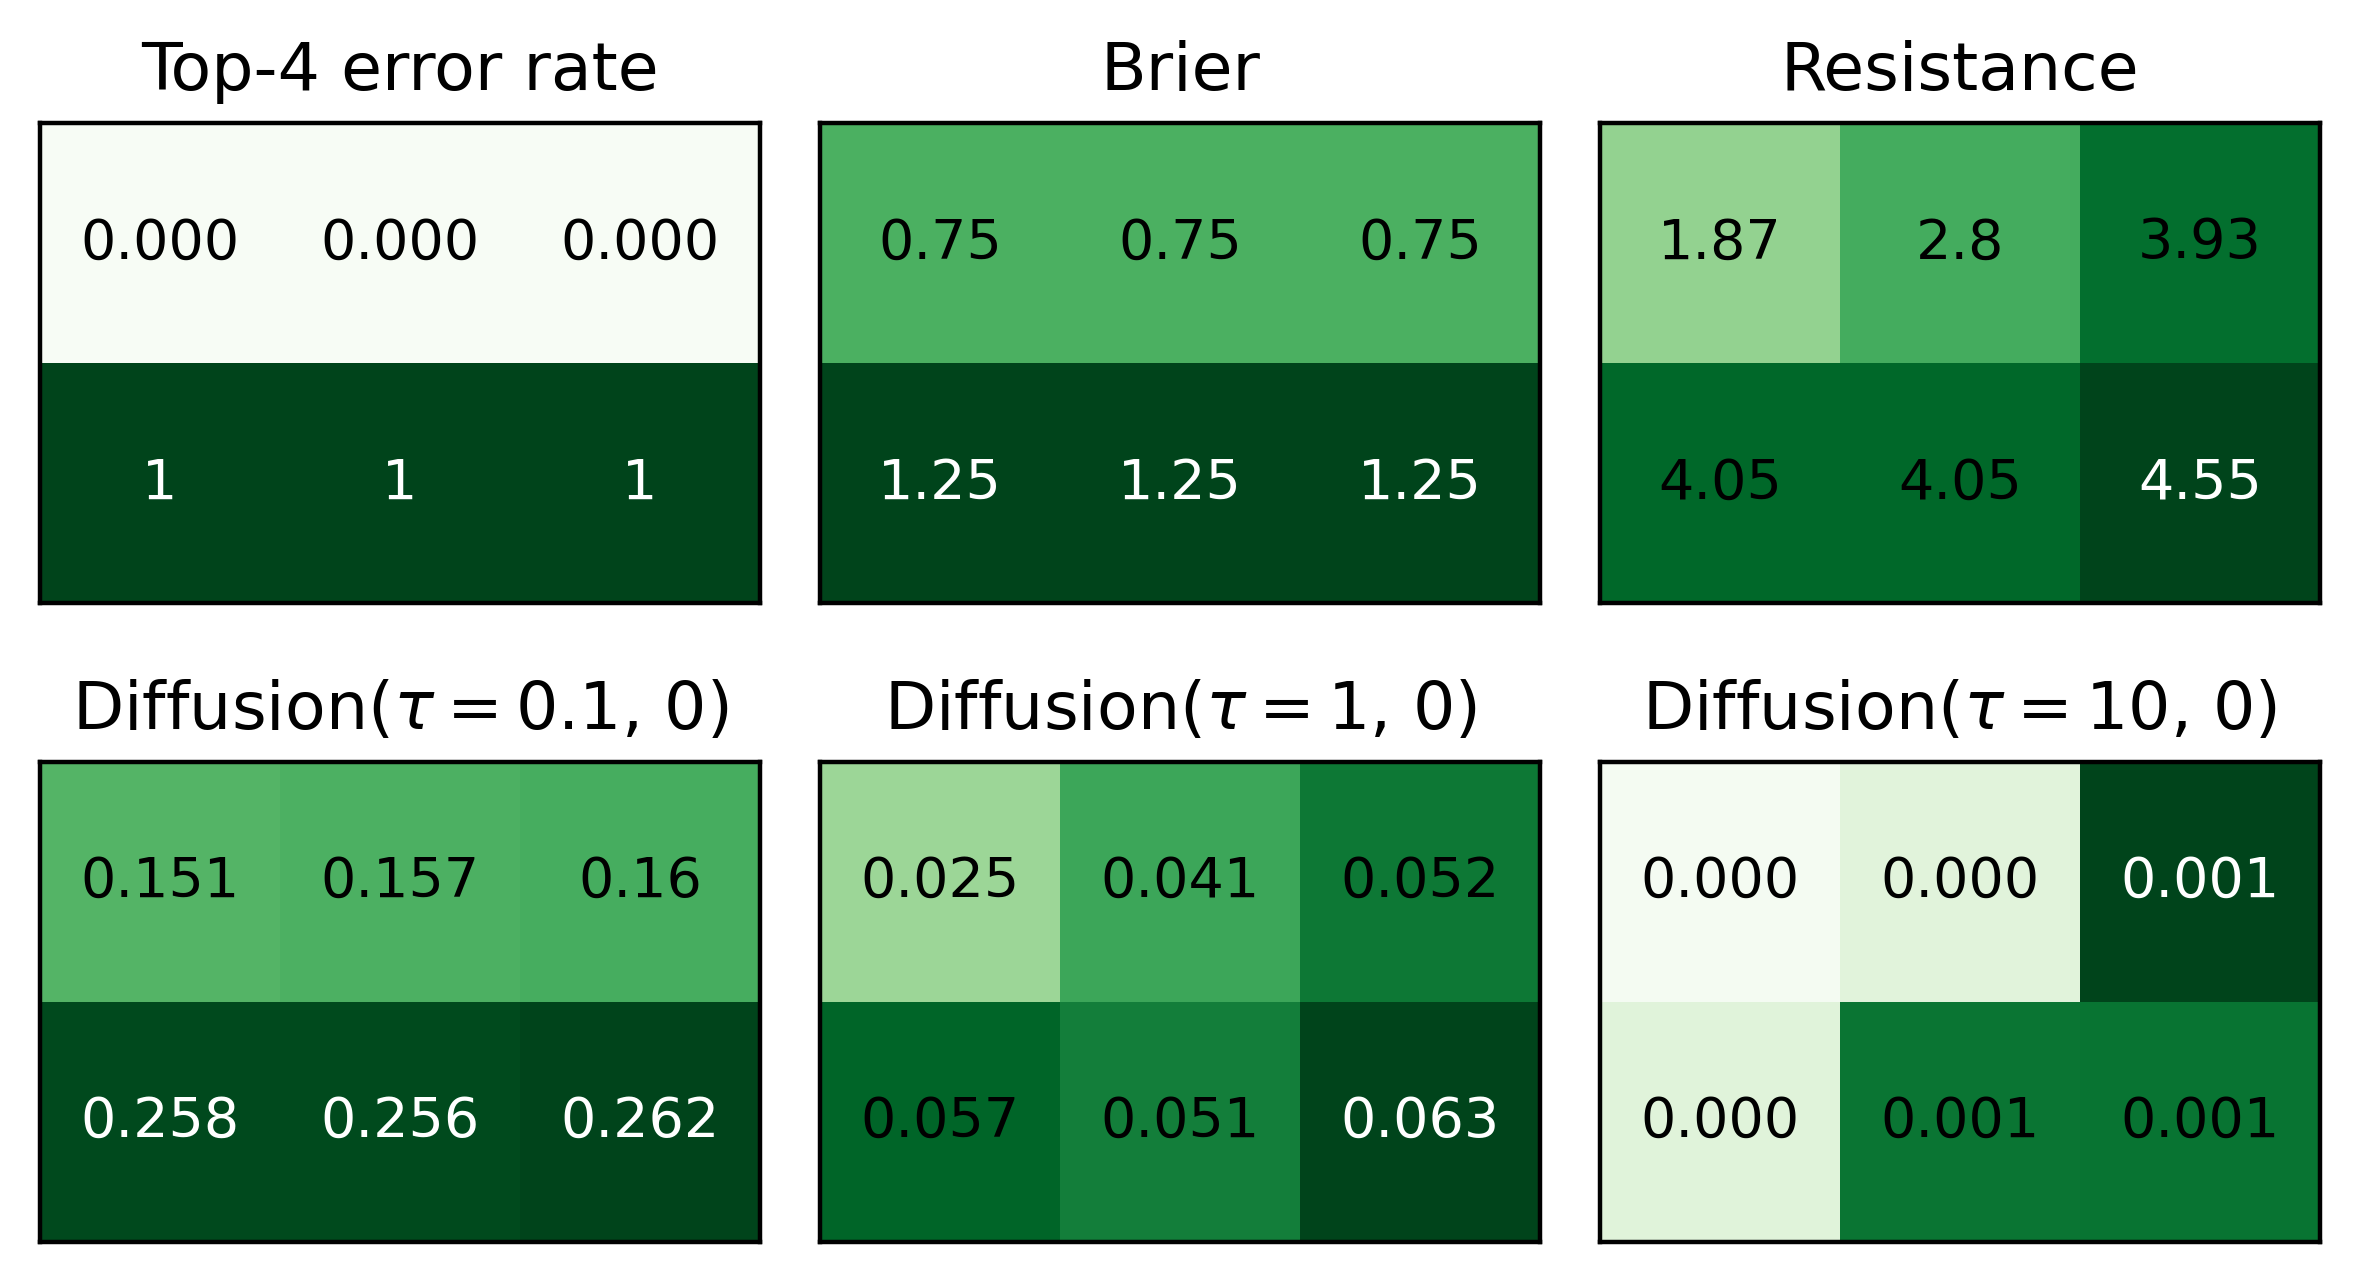

In [129]:
fig, axs = plt.subplots(2, 3, figsize=(6, 3.5), dpi=400)

score_ix = 0
for row in range(axs.shape[0]):
    for col in range(axs.shape[1]):
        ax = axs[row, col]
        entry = scores[score_ix]
        score_ix += 1
    
        # Handle both "resistance" and {"diffusion": {"alpha": 0.1}}
        if isinstance(entry, str):
            name, kwargs = entry, {}
        elif isinstance(entry, dict):
            if len(entry) != 1:
                raise ValueError(f"Invalid score entry: {entry}")
            name, kwargs = next(iter(entry.items()))
        else:
            raise TypeError(f"Unsupported score format: {entry}")
    
        # Build label with unnamed parameter values
        if kwargs:
            param_str = "(" + ", ".join(str(v) for v in kwargs.values()) + ")"
        else:
            param_str = ""
    
        if name in ["top_k_error_rate"]:
            method_name = name
            name = f"Top-{kwargs['k']} error rate"
            param_str = ""
        else:
            method_name = f"{name}_score"
        if name in ["diffusion"]:
            number = param_str[1:-1]
            param_str = r'($\tau=$' + number + ')'
        method_specs = str.capitalize(f"{name}{param_str}".replace(", positive", ""))
    
        values = []
        for task in [task_a, task_b, task_c, task_d, task_e, task_f]:
            value = getattr(task, method_name)(**kwargs)
            values.append(value)
    
        data = np.array(values).reshape(2, 3)
        data_no_inf = data.copy()
        data_no_inf[data_no_inf == np.inf] = 1e3
        values = []
        
        proportion = 1
        vmax = proportion * data_no_inf.max()
        
        ax.imshow(data_no_inf, vmin=0, vmax=vmax, cmap="Greens")
    
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                val = data[i, j]
                text_color = "white" if val / vmax > 0.9 else "black"
                
                # Format to 3 significant digits, then truncate decimals if needed
                if abs(val) < 0.0005:
                    formatted = "0.000"
                else:
                    formatted = f"{val:.3g}"
                    if 'e' not in formatted:
                        # Round to max 3 decimal places and strip trailing zeros
                        formatted = f"{float(formatted):.3f}".rstrip('0').rstrip('.')
                
                ax.text(j, i, formatted,
                         ha="center", va="center", color=text_color)
                
        ax.set_title(method_specs)
        ax.get_yaxis().set_visible(False)
        ax.get_xaxis().set_visible(False)
    
plt.tight_layout() 

#plt.savefig("images/toy_table_horiz.pdf", format="pdf")
plt.show()

In [141]:
scores = [
            #"logarithmic",
            {"top_k_error_rate": {"k": 4}},
            "brier", 
            #{"laplace": {"convention": "positive"}}, 
            "resistance", 
            #{"diffusion": {"tau": 0.01, "convention": "positive", "mu": mu}}, 
            {"diffusion": {"tau": 0.1, "convention": "positive"}}, 
            {"diffusion": {"tau": 1, "convention": "positive"}}, 
            {"diffusion": {"tau": 10, "convention": "positive"}},
            {"diffusion": {"tau": 0.1, "convention": "positive", "mu": mu}}, 
            {"diffusion": {"tau": 1, "convention": "positive", "mu": mu}}, 
            {"diffusion": {"tau": 10, "convention": "positive", "mu": mu}}
        ]

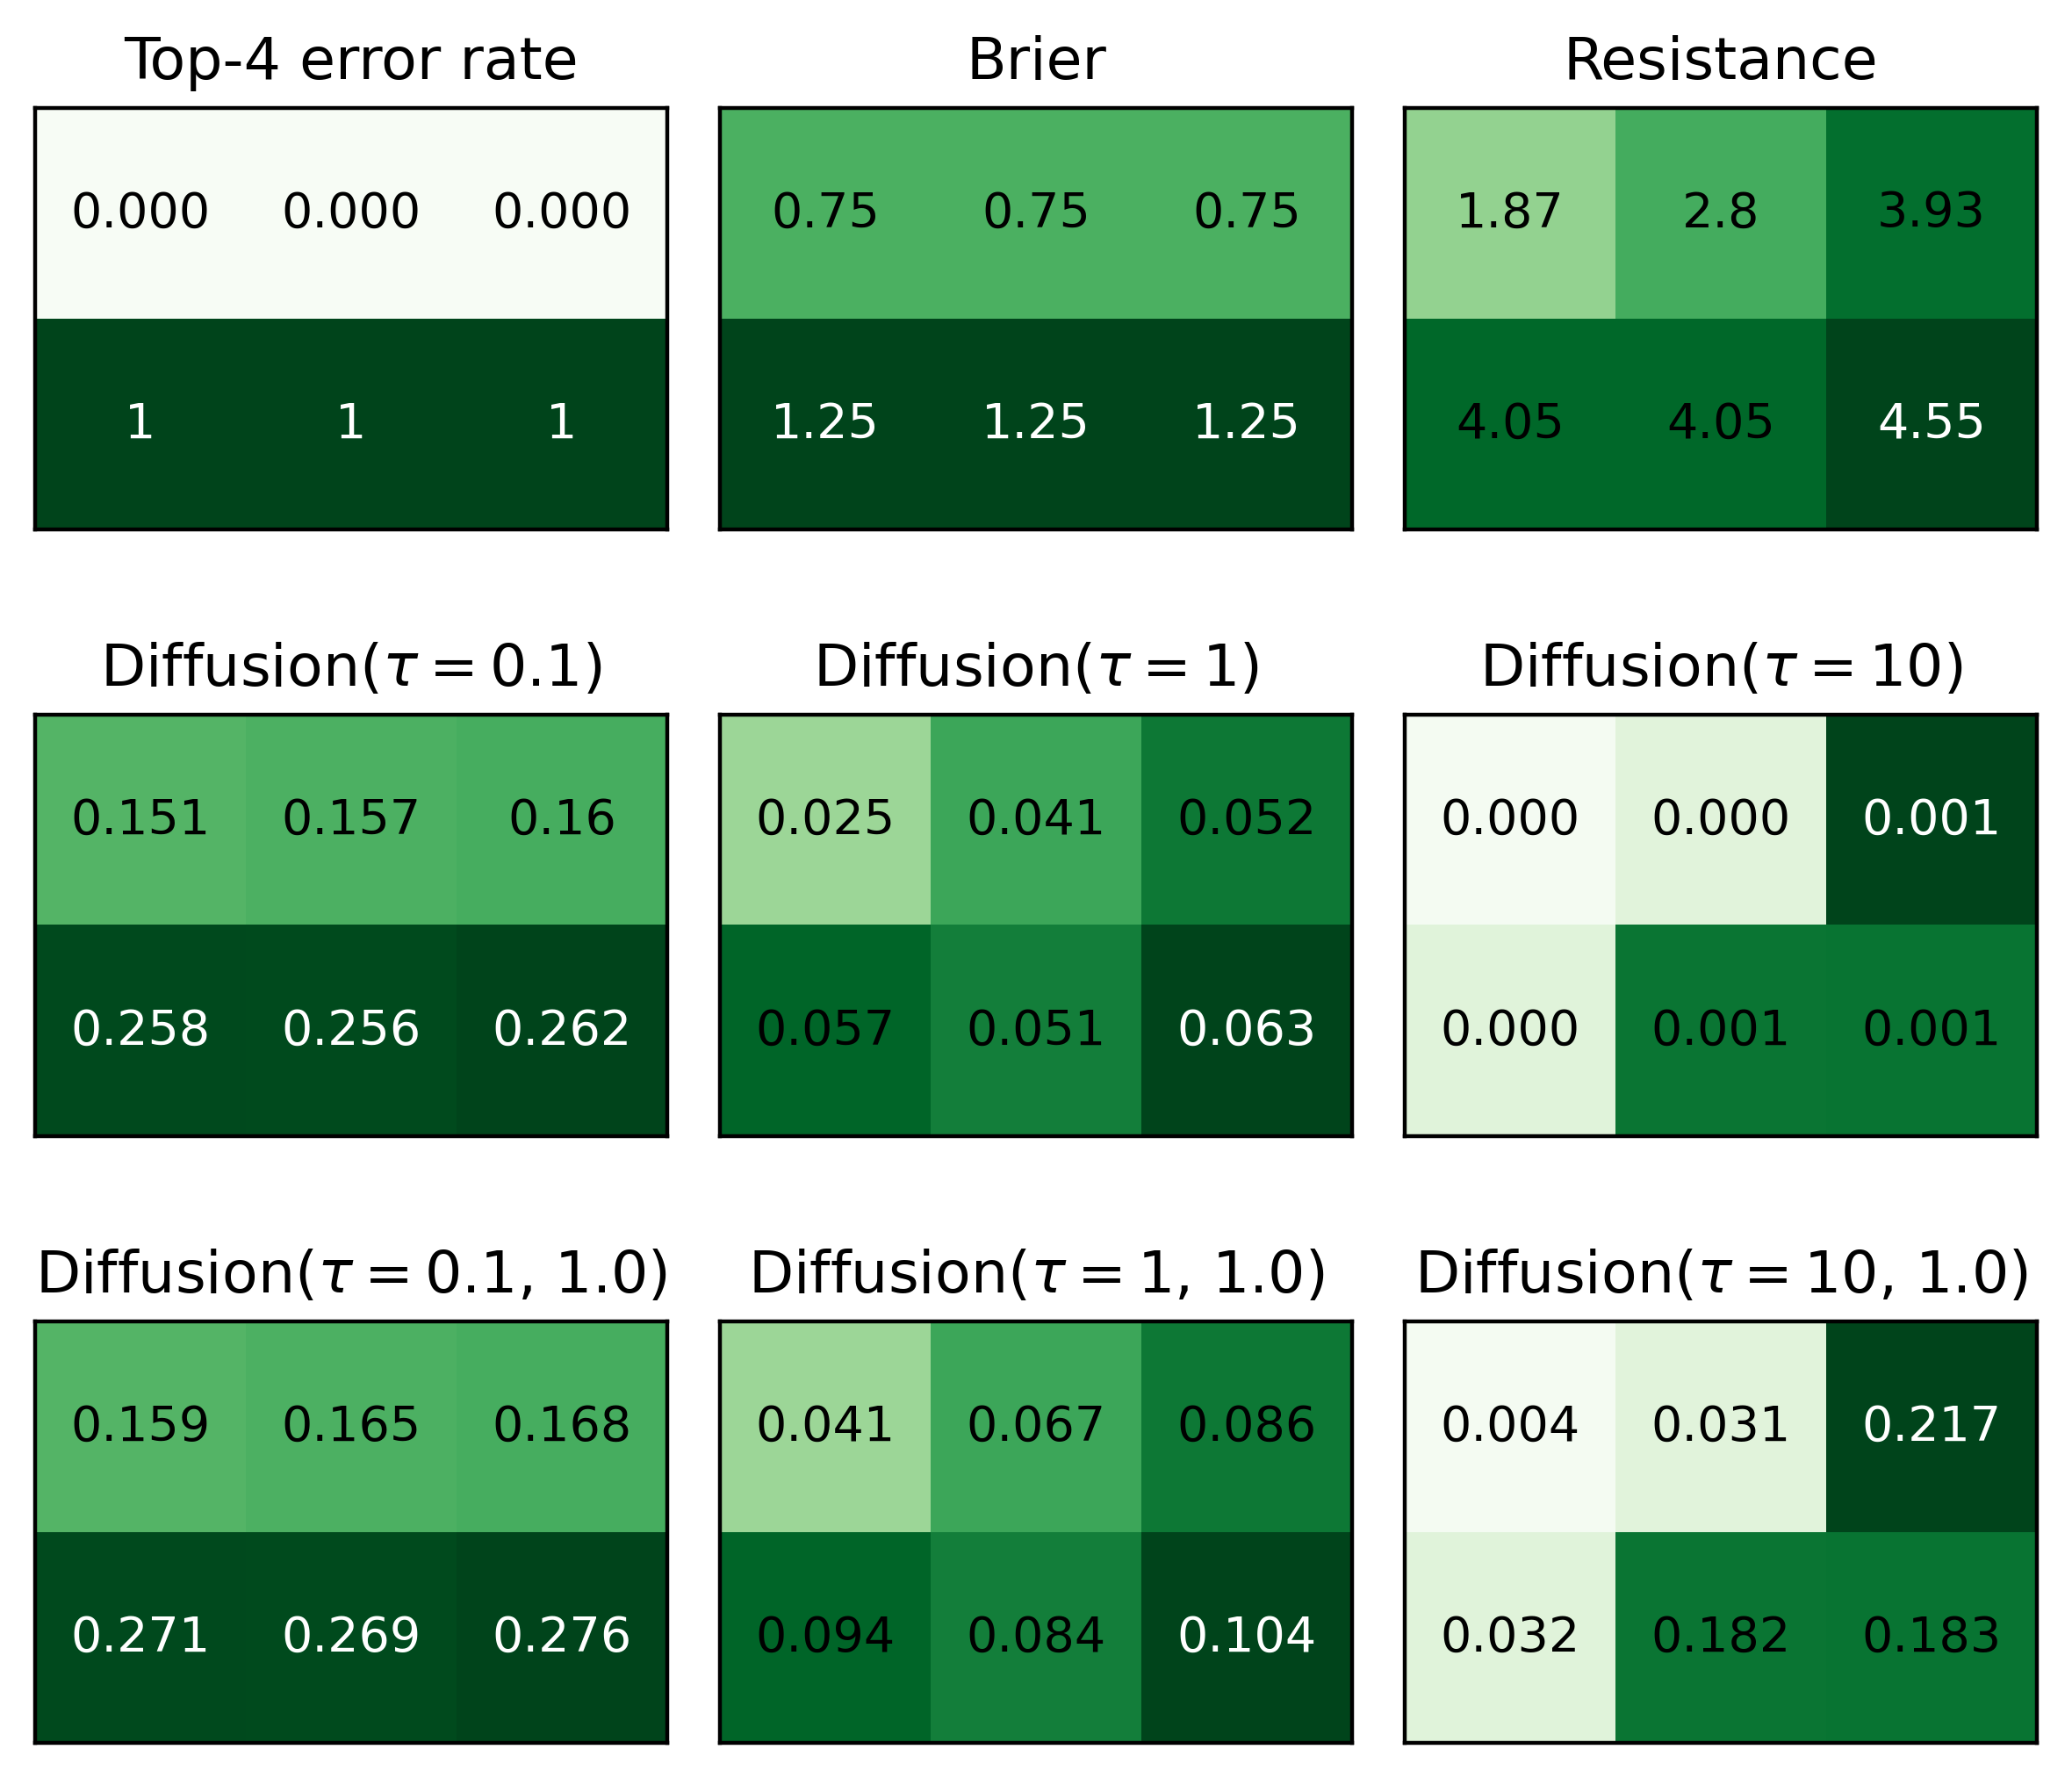

In [142]:
fig, axs = plt.subplots(3, 3, figsize=(6, 5.5), dpi=400)

score_ix = 0
for row in range(axs.shape[0]):
    for col in range(axs.shape[1]):
        ax = axs[row, col]
        entry = scores[score_ix]
        score_ix += 1
    
        # Handle both "resistance" and {"diffusion": {"alpha": 0.1}}
        if isinstance(entry, str):
            name, kwargs = entry, {}
        elif isinstance(entry, dict):
            if len(entry) != 1:
                raise ValueError(f"Invalid score entry: {entry}")
            name, kwargs = next(iter(entry.items()))
        else:
            raise TypeError(f"Unsupported score format: {entry}")
    
        # Build label with unnamed parameter values
        if kwargs:
            param_str = "(" + ", ".join(str(v) for v in kwargs.values()) + ")"
        else:
            param_str = ""
    
        if name in ["top_k_error_rate"]:
            method_name = name
            name = f"Top-{kwargs['k']} error rate"
            param_str = ""
        else:
            method_name = f"{name}_score"
        if name in ["diffusion"]:
            number = param_str[1:-1]
            param_str = r'($\tau=$' + number + ')'
        method_specs = str.capitalize(f"{name}{param_str}".replace(", positive", ""))
    
        values = []
        for task in [task_a, task_b, task_c, task_d, task_e, task_f]:
            value = getattr(task, method_name)(**kwargs)
            values.append(value)
    
        data = np.array(values).reshape(2, 3)
        data_no_inf = data.copy()
        data_no_inf[data_no_inf == np.inf] = 1e3
        values = []
        
        proportion = 1
        vmax = proportion * data_no_inf.max()
        
        ax.imshow(data_no_inf, vmin=0, vmax=vmax, cmap="Greens")
    
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                val = data[i, j]
                text_color = "white" if val / vmax > 0.9 else "black"
                
                # Format to 3 significant digits, then truncate decimals if needed
                if abs(val) < 0.0005:
                    formatted = "0.000"
                else:
                    formatted = f"{val:.3g}"
                    if 'e' not in formatted:
                        # Round to max 3 decimal places and strip trailing zeros
                        formatted = f"{float(formatted):.3f}".rstrip('0').rstrip('.')
                
                ax.text(j, i, formatted,
                         ha="center", va="center", color=text_color)
                
        ax.set_title(method_specs)
        ax.get_yaxis().set_visible(False)
        ax.get_xaxis().set_visible(False)
    
plt.tight_layout() 

#plt.savefig("images/toy_table_horiz.pdf", format="pdf")
plt.show()

In [154]:
mu1 = 1#eigenvalues[1]
mu2 = 2#eigenvalues[2]

scores = [
            #"logarithmic",
            {"top_k_error_rate": {"k": 4}},
            "brier", 
            #{"laplace": {"convention": "positive"}}, 
            "resistance", 
            #{"diffusion": {"tau": 0.01, "convention": "positive", "mu": mu}}, 
            {"diffusion": {"tau": 0.1, "convention": "positive"}}, 
            {"diffusion": {"tau": 1, "convention": "positive"}}, 
            {"diffusion": {"tau": 30, "convention": "positive"}},
            {"diffusion": {"tau": 0.1, "convention": "positive", "mu": mu1}}, 
            {"diffusion": {"tau": 1, "convention": "positive", "mu": mu1}}, 
            {"diffusion": {"tau": 30, "convention": "positive", "mu": mu1}},
            {"diffusion": {"tau": 0.1, "convention": "positive", "mu": mu2}}, 
            {"diffusion": {"tau": 1, "convention": "positive", "mu": mu2}}, 
            {"diffusion": {"tau": 30, "convention": "positive", "mu": mu2}}
        ]

[[0. 0. 0.]
 [1. 1. 1.]] 

[[0.6 0.6 0.6]
 [1.  1.  1. ]] 

[[0.41176471 0.61437908 0.8627451 ]
 [0.88888889 0.88888889 1.        ]] 

[[0.57675467 0.597299   0.61028372]
 [0.98304568 0.97753776 1.        ]] 

[[0.39061044 0.64064878 0.82660446]
 [0.89732009 0.80262581 1.        ]] 

[[0.0167133  0.01681204 1.00012695]
 [0.01681204 0.99999999 1.        ]] 

[[0.57675467 0.597299   0.61028372]
 [0.98304568 0.97753776 1.        ]] 

[[0.39061044 0.64064878 0.82660446]
 [0.89732009 0.80262581 1.        ]] 

[[0.0167133  0.01681204 1.00012695]
 [0.01681204 0.99999999 1.        ]] 

[[0.57675467 0.597299   0.61028372]
 [0.98304568 0.97753776 1.        ]] 

[[0.39061044 0.64064878 0.82660446]
 [0.89732009 0.80262581 1.        ]] 

[[0.0167133  0.01681204 1.00012695]
 [0.01681204 0.99999999 1.        ]] 



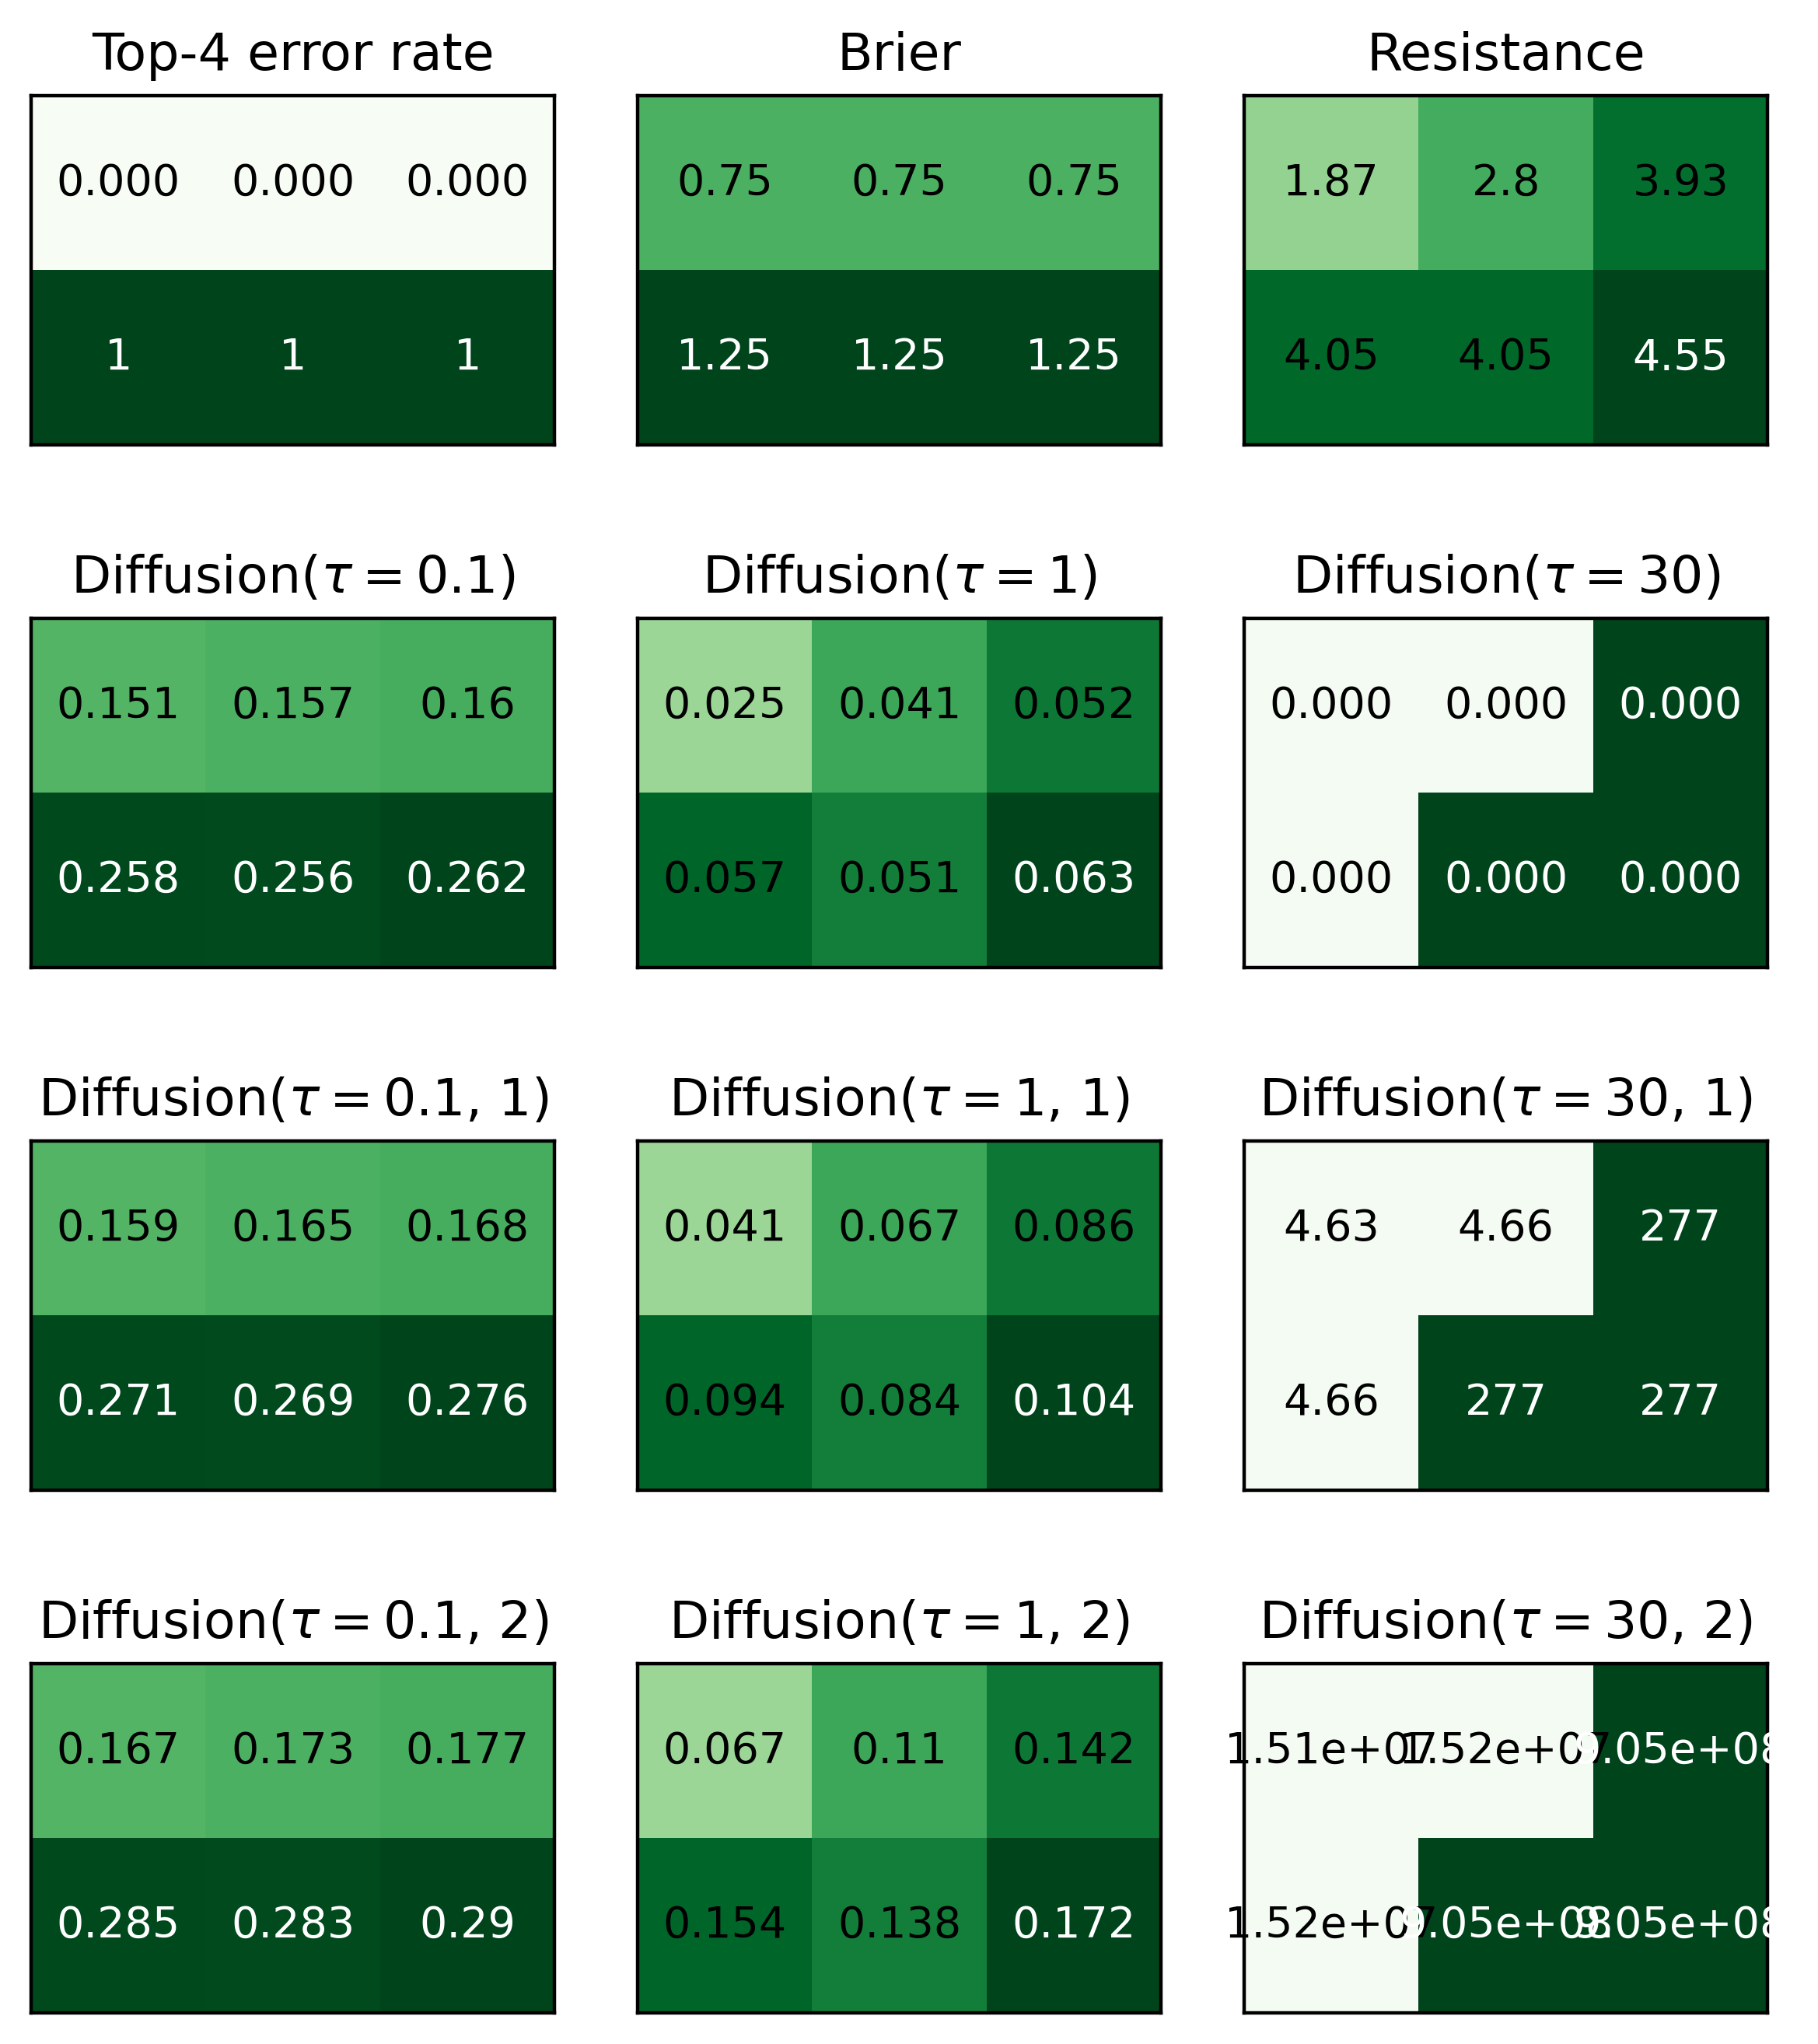

In [155]:
fig, axs = plt.subplots(4, 3, figsize=(6, 7), dpi=400)

score_ix = 0
for row in range(axs.shape[0]):
    for col in range(axs.shape[1]):
        ax = axs[row, col]
        entry = scores[score_ix]
        score_ix += 1
    
        # Handle both "resistance" and {"diffusion": {"alpha": 0.1}}
        if isinstance(entry, str):
            name, kwargs = entry, {}
        elif isinstance(entry, dict):
            if len(entry) != 1:
                raise ValueError(f"Invalid score entry: {entry}")
            name, kwargs = next(iter(entry.items()))
        else:
            raise TypeError(f"Unsupported score format: {entry}")
    
        # Build label with unnamed parameter values
        if kwargs:
            param_str = "(" + ", ".join(str(v) for v in kwargs.values()) + ")"
        else:
            param_str = ""
    
        if name in ["top_k_error_rate"]:
            method_name = name
            name = f"Top-{kwargs['k']} error rate"
            param_str = ""
        else:
            method_name = f"{name}_score"
        if name in ["diffusion"]:
            number = param_str[1:-1]
            param_str = r'($\tau=$' + number + ')'
        method_specs = str.capitalize(f"{name}{param_str}".replace(", positive", ""))
    
        values = []
        for task in [task_a, task_b, task_c, task_d, task_e, task_f]:
            value = getattr(task, method_name)(**kwargs)
            values.append(value)
    
        data = np.array(values).reshape(2, 3)
        data_no_inf = data.copy()
        data_no_inf[data_no_inf == np.inf] = 1e3
        values = []
        
        proportion = 1
        vmax = proportion * data_no_inf.max()
        
        ax.imshow(data_no_inf, vmin=0, vmax=vmax, cmap="Greens")
    
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                val = data[i, j]
                text_color = "white" if val / vmax > 0.9 else "black"
                
                # Format to 3 significant digits, then truncate decimals if needed
                if abs(val) < 0.0005:
                    formatted = "0.000"
                else:
                    formatted = f"{val:.3g}"
                    if 'e' not in formatted:
                        # Round to max 3 decimal places and strip trailing zeros
                        formatted = f"{float(formatted):.3f}".rstrip('0').rstrip('.')
                
                ax.text(j, i, formatted,
                         ha="center", va="center", color=text_color)

        # Check ratios
        data = data/data[-1,-1]
        print(data, "\n")
                
        ax.set_title(method_specs)
        ax.get_yaxis().set_visible(False)
        ax.get_xaxis().set_visible(False)
    
plt.tight_layout() 

#plt.savefig("images/toy_table_horiz.pdf", format="pdf")
plt.show()

# Karate club

In [125]:
# Spectrum of Karate club network

G = nx.karate_club_graph()  # Example: Zachary's Karate Club graph
L = nx.laplacian_matrix(G).toarray()
eigenvalues = np.linalg.eigvalsh(L)  # eigvalsh for symmetric matrices
eigenvalues = np.sort(eigenvalues)

print("Laplacian Spectrum:")
print(np.round(eigenvalues, 2))

Laplacian Spectrum:
[-0.    1.19  2.39  2.93  2.97  3.06  3.12  3.71  3.8   4.16  4.54  4.7
  4.98  5.17  5.59  6.45  6.98  9.18 10.01 10.22 11.87 12.08 14.38 14.89
 17.03 19.32 21.36 22.78 25.56 29.69 37.99 41.83 45.99 52.07]


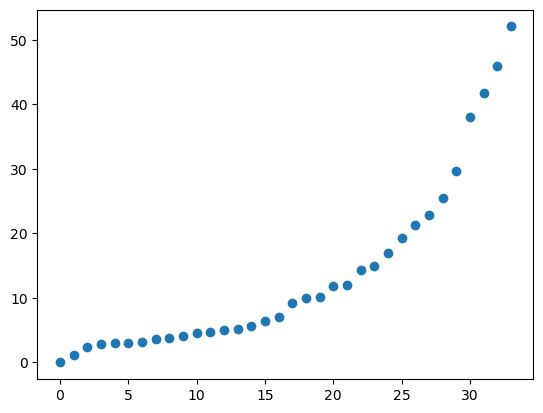

In [126]:
plt.scatter(np.arange(len(eigenvalues)), eigenvalues)